In [1]:
import pickle

# Load
f = open("data/first_10_events.pickle", "rb")
events = pickle.load(f)

# Print table (tag) names:
print('\n'.join(events.keys()))

# Retrieve table (tag):
print(type(events["reconstructedPhysicsEvent"]))
print(events["reconstructedPhysicsEvent"])
 

reconstructedPhysicsEvent
comment
dataVersionString
ccdbContext
reaction
vertex
origin
product
momentum
tagmBeamPhoton
tagmChannel
taghBeamPhoton
taghChannel
ecalShower
ecalShowerProperties
fcalShower
fcalCorrelations
fcalShowerClassification
fcalShowerProperties
fcalShowerNBlocks
fcalShowerIsNearBorder
fcalHit
bcalShower
preshower
width
bcalCluster
bcalCorrelations
bcalLayers
ccalShower
chargedTrack
trackFit
trackFlags
hitlayers
expectedhits
mcmatch
dEdxDC
CDCAmpdEdx
CDCdEdxTrunc
FDCdEdxTrunc
fdcTrackPos
exitParams
startHit
ctofPoint
tofPoint
tofStatus
tofEnergyDeposition
dircHit
fmwpcHit
RFtime
trigger
triggerEnergySums
triggerFcal2EnergySum
electronBeam
detectorMatches
bcalMatchParams
ecalMatchParams
ecalSingleHitMatchParams
fcalMatchParams
fcalEnergyParams
fcalSingleHitMatchParams
ctofMatchParams
fmwpcMatchParams
fmwpcData
tofMatchParams
tofDedx
scMatchParams
dircMatchParams
dircMatchHit
bcalDOCAtoTrack
fcalDOCAtoTrack
tflightPCorrelation
hitStatistics
startCounters
cdcStraws
fdcPs

In [2]:
print(type(events['chargedTrack']))
print(events['chargedTrack'].columns)
print(f"ptype: {type(events['chargedTrack']['ptype'])}")
print(f"reconstructedPhysicsEvent: {type(events['chargedTrack']['reconstructedPhysicsEvent'])}")

<class 'pandas.DataFrame'>
Index(['reconstructedPhysicsEvent', 'jtag', 'ptype', 'candidateId'], dtype='object')
ptype: <class 'pandas.Series'>
reconstructedPhysicsEvent: <class 'pandas.Series'>


In [3]:
print(events['chargedTrack'])
# print(events['chargedTrack']['candidateId'])

    reconstructedPhysicsEvent jtag     ptype  candidateId
0                           0       Positron            1
1                           0            Pi+            1
2                           0             K+            1
3                           0         Proton            1
4                           1       Electron            2
..                        ...  ...       ...          ...
71                          9         Proton            2
72                          9       Positron            3
73                          9            Pi+            3
74                          9             K+            3
75                          9         Proton            3

[76 rows x 4 columns]


In [4]:
print(events['trackFit'])


    chargedTrack  Ndof       chisq         x0         y0         z0        px  \
0              0    23   25.049126  -0.065998   0.094348  74.735817  0.510050   
1              1    23   25.444756  -0.063780   0.089663  74.732773  0.506897   
2              2    23   24.193354  -0.064484   0.091142  74.728912  0.507608   
3              3    23   24.221533  -0.065516   0.093318  74.726288  0.509361   
4              4     1  909.703918 -62.071316  45.520977  75.431541  0.557011   
..           ...   ...         ...        ...        ...        ...       ...   
71            71    17   22.313856  -0.019457   0.000655  53.288177 -0.353521   
72            72    22   16.558914   0.178181   0.041321  52.144451  0.057830   
73            73    22   16.802090   0.170086   0.040357  52.144604  0.057804   
74            74    22   16.683413   0.177912   0.041399  52.148975  0.057656   
75            75    22   17.348902   0.195325   0.043619  52.130936  0.057595   

          py        pz     

In [5]:
# Build a reusable, event-aware view for track-fit level plotting
import numpy as np
import pandas as pd

charged_cols = ["reconstructedPhysicsEvent", "candidateId", "ptype", "jtag"]
trackfit_view = events["trackFit"].join(
    events["chargedTrack"][charged_cols],
    on="chargedTrack",
    how="left",
    rsuffix="_charged"
).copy()

# Reduced chi2 used to pick the best mass hypothesis per candidate
trackfit_view["chi2_ndof"] = np.where(
    trackfit_view["Ndof"] > 0,
    trackfit_view["chisq"] / trackfit_view["Ndof"],
    np.inf,
 )

# A physics candidate is identified by (event, candidateId)
candidate_keys = ["reconstructedPhysicsEvent", "candidateId"]

# Pick the hypothesis with the minimum chi2/Ndof for each candidate
best_idx = trackfit_view.groupby(candidate_keys, dropna=False)["chi2_ndof"].idxmin()
best_hypothesis = trackfit_view.loc[best_idx].reset_index(drop=True)

print(f"trackfit_view rows: {len(trackfit_view)}")
print(f"best_hypothesis rows: {len(best_hypothesis)}")
print("Best-hypothesis ptype counts:")
print(best_hypothesis["ptype"].value_counts(dropna=False))

trackfit_view rows: 76
best_hypothesis rows: 17
Best-hypothesis ptype counts:
ptype
K+            4
Proton        4
AntiProton    3
Positron      2
Pi-           2
Pi+           1
Electron      1
Name: count, dtype: int64


Pi+ entries passing best-hypothesis selection: 1


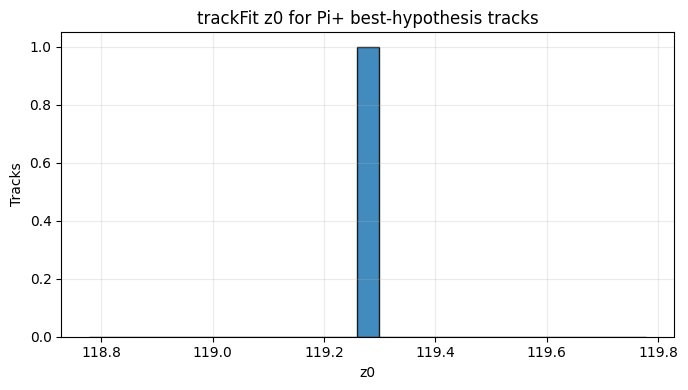

In [6]:
# z0 distribution for Pi+ when Pi+ is the best hypothesis for that candidate
import matplotlib.pyplot as plt

pi_plus_best = best_hypothesis.loc[best_hypothesis["ptype"] == "Pi+"].copy()
z0_pi_plus_best = pi_plus_best["z0"].dropna()

print(f"Pi+ entries passing best-hypothesis selection: {len(z0_pi_plus_best)}")

plt.figure(figsize=(7, 4))
plt.hist(z0_pi_plus_best, bins=25, alpha=0.85, edgecolor="black")
plt.xlabel("z0")
plt.ylabel("Tracks")
plt.title("trackFit z0 for Pi+ best-hypothesis tracks")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Entries using best chisq/Ndof per candidate: 17


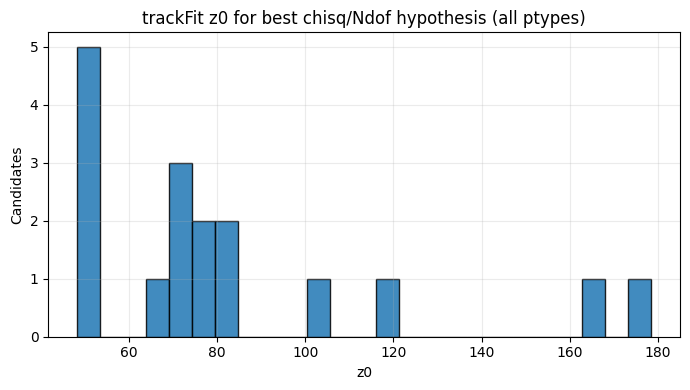

In [7]:
# z0 distribution for the best-fit hypothesis per candidate (across all ptypes)
z0_best_all_ptypes = best_hypothesis["z0"].dropna()

print(f"Entries using best chisq/Ndof per candidate: {len(z0_best_all_ptypes)}")

plt.figure(figsize=(7, 4))
plt.hist(z0_best_all_ptypes, bins=25, alpha=0.85, edgecolor="black")
plt.xlabel("z0")
plt.ylabel("Candidates")
plt.title("trackFit z0 for best chisq/Ndof hypothesis (all ptypes)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fcalShower rows: 29
fcalShower columns: ['reconstructedPhysicsEvent', 'jtag', 'x', 'y', 'z', 't', 'E', 'xerr', 'yerr', 'zerr', 'terr', 'Eerr', 'xycorr', 'xzcorr', 'yzcorr', 'tzcorr', 'Ezcorr']
Using energy column: E
Entries with valid energy: 29


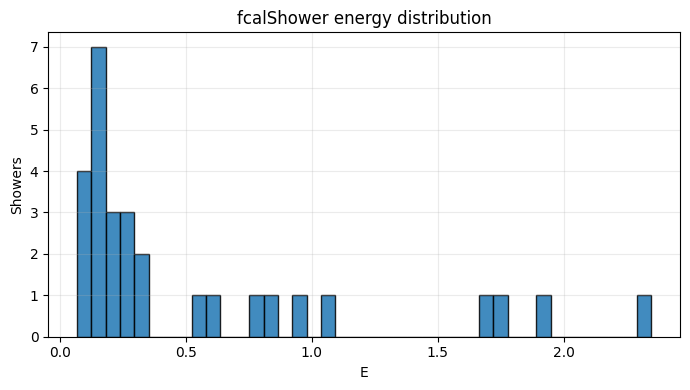

In [8]:
# Energy distribution from fcalShower
fcal_df = events["fcalShower"]
print(f"fcalShower rows: {len(fcal_df)}")
print("fcalShower columns:", list(fcal_df.columns))

energy_col = next((c for c in ["energy", "E", "e"] if c in fcal_df.columns), None)
if energy_col is None:
    energy_like = [c for c in fcal_df.columns if "energy" in c.lower()]
    if not energy_like:
        raise KeyError("Could not find an energy column in events['fcalShower']")
    energy_col = energy_like[0]

fcal_energy = pd.to_numeric(fcal_df[energy_col], errors="coerce").dropna()
print(f"Using energy column: {energy_col}")
print(f"Entries with valid energy: {len(fcal_energy)}")

plt.figure(figsize=(7, 4))
plt.hist(fcal_energy, bins=40, alpha=0.85, edgecolor="black")
plt.xlabel(f"{energy_col}")
plt.ylabel("Showers")
plt.title("fcalShower energy distribution")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()